# Задание 4.8

На отрезке $[a,b]$, лежащем на числовой оси, наудачу выбирается первая точка с координатой $x$, после чего на отрезке $[a,x]$ наудачу выбирается вторая точка с координатой $y$. Найдите вероятности следующих событий: $A$ — вторая точка ближе к $b$, чем первая к $a$; $B$ — расстояние между точками $x$ и $y$ меньше половины длины отрезка; $C$ — первая точка ближе ко второй, чем к точке $b$.

Постройте график зависимости относительной частоты $\hat p(A)=\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N=150\,000$ и приведите оценку вероятности $\hat p(A)=\dfrac{N_A}{N}$ для $N=150\,000$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Нормировка.** Сделаем замену $x\mapsto\dfrac{x-a}{b-a}$, $y\mapsto\dfrac{y-a}{b-a}$ — все условия (сравнение расстояний) сохраняются, и можно считать $[a,b]=[0,1]$.

**Модель.** $x\sim U[0,1]$, а при известном $x$ точка $y\sim U[0,x]$. Пара $(x,y)$ лежит в треугольнике $\Omega=\{0\le y\le x\le1\}$, но распределена в нём **неравномерно** — с плотностью

$$
f(x,y)=f_x(x)\,f_{y\mid x}(y)=1\cdot\frac1x,\qquad 0<y<x<1 .
$$

Поэтому вероятность события $G\subset\Omega$ — не отношение площадей, а

$$
\mathbb P(G)=\iint_G\frac{dx\,dy}{x}=\int_0^1\frac{\ell_G(x)}{x}\,dx,
$$

где $\ell_G(x)$ — длина множества тех $y\in[0,x]$, при которых $(x,y)\in G$ (условная вероятность $\ell_G(x)/x$ при фиксированном $x$).

**$A$: $\ 1-y<x$, т.е. $y>1-x$.** При $x\le\frac12$ таких $y\in[0,x]$ нет; при $x>\frac12$ длина $\ell=x-(1-x)=2x-1$:

$$
\mathbb P(A)=\int_{1/2}^{1}\frac{2x-1}{x}\,dx=\Big[2x-\ln x\Big]_{1/2}^{1}=1-\ln2\approx0{,}306853 .
$$

**$B$: $\ x-y<\frac12$, т.е. $y>x-\frac12$.** При $x\le\frac12$ подходят все $y$ ($\ell=x$); при $x>\frac12$ $\ \ell=\frac12$:

$$
\mathbb P(B)=\int_0^{1/2}1\,dx+\int_{1/2}^{1}\frac{dx}{2x}=\frac12+\frac{\ln2}{2}\approx0{,}846574 .
$$

**$C$: $\ x-y<1-x$, т.е. $y>2x-1$.** При $x\le\frac12$ подходят все $y$; при $x>\frac12$ $\ \ell=x-(2x-1)=1-x$:

$$
\mathbb P(C)=\frac12+\int_{1/2}^{1}\frac{1-x}{x}\,dx=\frac12+\Big[\ln x-x\Big]_{1/2}^{1}=\ln2\approx0{,}693147 .
$$

Ответы не зависят от $a$ и $b$; в программе для наглядности взят отрезок $[a,b]=[2,7]$.

P(A) = 1 - log(2) ≈ 0.306853
P(B) = log(2)/2 + 1/2 ≈ 0.846574
P(C) = log(2) ≈ 0.693147
A: p̂ = 0.30381 (N = 150 000),  P = 0.30685,  |p̂ - P| = 3.0e-03
B: p̂ = 0.84793 (N = 150 000),  P = 0.84657,  |p̂ - P| = 1.4e-03
C: p̂ = 0.69493 (N = 150 000),  P = 0.69315,  |p̂ - P| = 1.8e-03


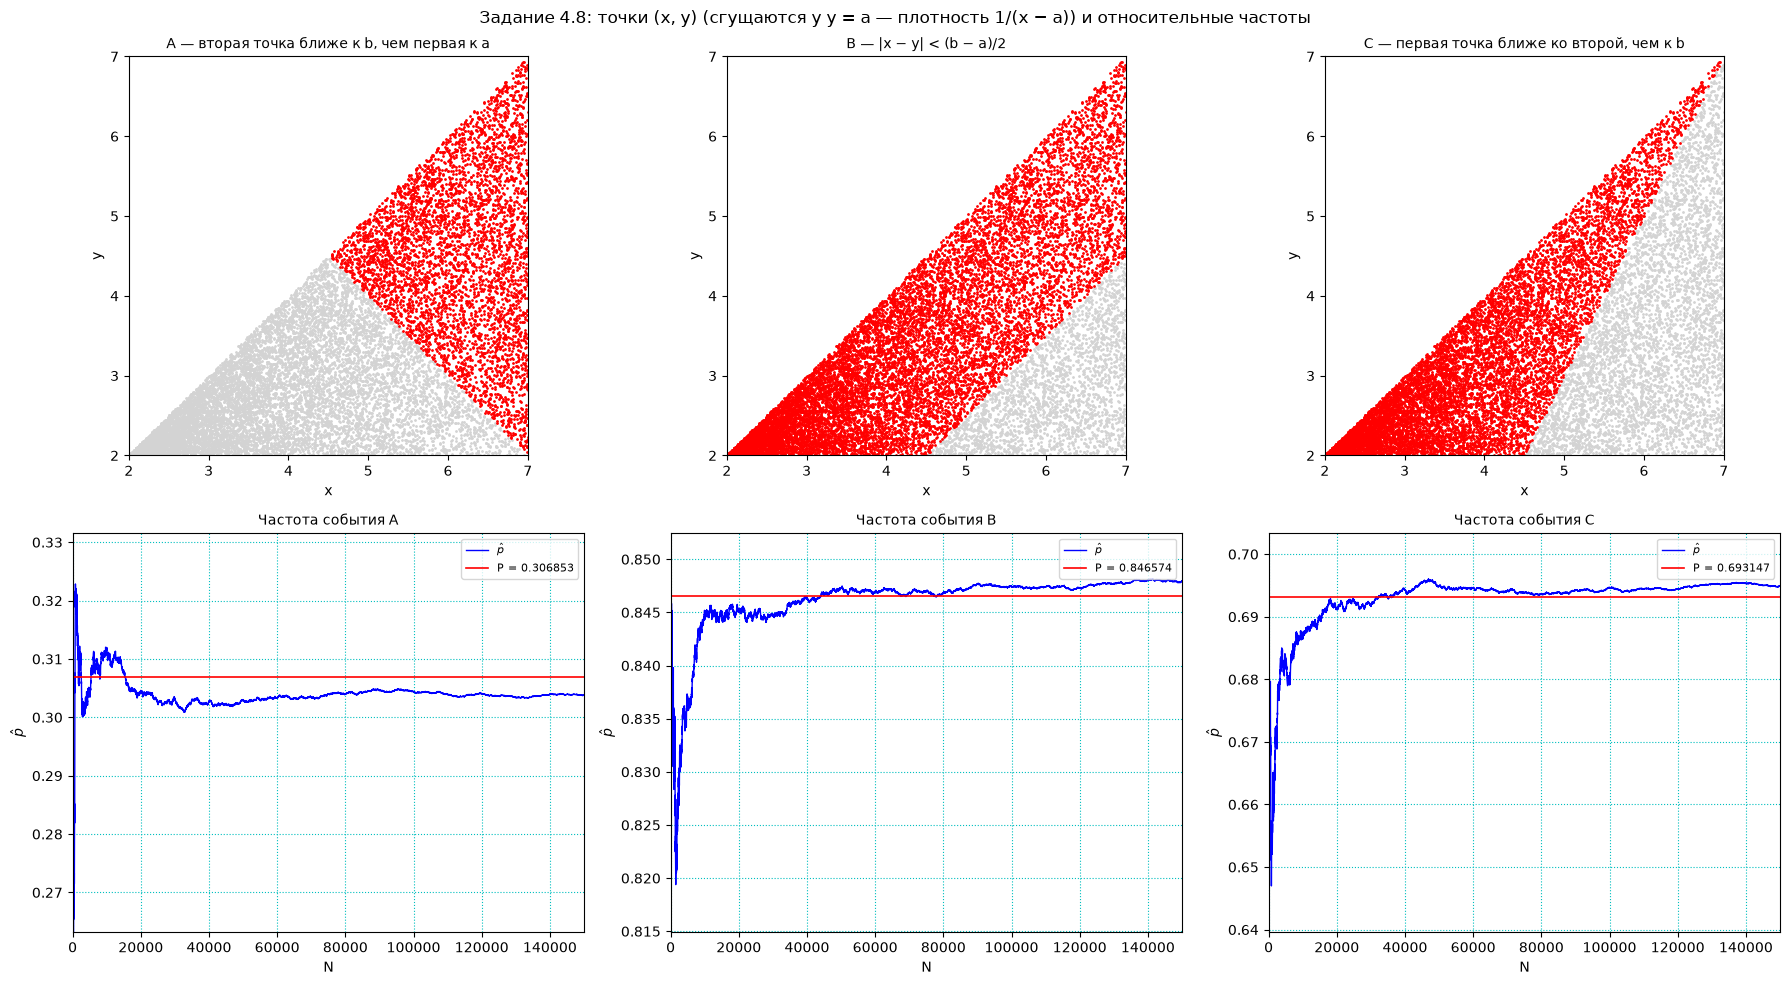

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точные вероятности: P(G) = ∫ ℓ_G(x)/x dx ----------
X = sp.symbols("x", positive=True)
h = sp.Rational(1, 2)
PA = sp.integrate((2*X - 1)/X, (X, h, 1))
PB = sp.integrate(1, (X, 0, h)) + sp.integrate(h/X, (X, h, 1))
PC = sp.integrate(1, (X, 0, h)) + sp.integrate((1 - X)/X, (X, h, 1))
exact = {"A": PA, "B": PB, "C": PC}
for k, v in exact.items():
    print(f"P({k}) = {sp.simplify(v)} ≈ {float(v):.6f}")

# ---------- Моделирование на отрезке [a, b] ----------
a, b, N = 2.0, 7.0, 150_000
x = rng.uniform(a, b, N)            # первая точка — наудачу на [a, b]
y = a + (x - a) * rng.random(N)     # вторая точка — наудачу на [a, x]
hits = {
    "A": (b - y) < (x - a),         # вторая точка ближе к b, чем первая к a
    "B": (x - y) < (b - a) / 2,     # |x - y| меньше половины длины отрезка
    "C": (x - y) < (b - x),         # первая точка ближе ко второй, чем к b
}
titles = {"A": "A — вторая точка ближе к b, чем первая к a",
          "B": "B — |x − y| < (b − a)/2",
          "C": "C — первая точка ближе ко второй, чем к b"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
s = slice(0, 15_000)
for j, ev in enumerate(hits):
    ax = axes[0, j]
    hh = hits[ev][s]
    ax.scatter(x[s][~hh], y[s][~hh], s=1, c="lightgray", rasterized=True)
    ax.scatter(x[s][hh], y[s][hh], s=1, c="red", rasterized=True)
    ax.set_xlim(a, b); ax.set_ylim(a, b); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title(titles[ev], fontsize=10)
    ph = plot_freq(axes[1, j], hits[ev], float(exact[ev]), f"Частота события {ev}")
    print(f"{ev}: p̂ = {ph:.5f} (N = 150 000),  P = {float(exact[ev]):.5f},  |p̂ - P| = {abs(ph - float(exact[ev])):.1e}")
fig.suptitle("Задание 4.8: точки (x, y) (сгущаются у y = a — плотность 1/(x − a)) и относительные частоты", fontsize=12)
fig.tight_layout()
plt.show()